# Rice Grain Classification

## 0. GPU Check

In [1]:
import torch

if torch.cuda.is_available():
    print(f"GPU ready: {torch.cuda.get_device_name(0)}")
    print(f"CUDA version : {torch.version.cuda}")
    print(f"cuDNN version: {torch.backends.cudnn.version()}")
    DEVICE = torch.device('cuda')
else:
    print("NO GPU DETECTED")
    DEVICE = torch.device('cpu')

print(f"\nUsing device: {DEVICE}")

GPU ready: NVIDIA GeForce RTX 3060
CUDA version : 12.1
cuDNN version: 90100

Using device: cuda


## 1. Imports

In [2]:
import os, cv2, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as mpl_cm
import seaborn as sns
from glob import glob
from collections import Counter
from scipy import stats
warnings.filterwarnings('ignore')

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast  # Mixed-precision

# torchvision
import torchvision.models as tv_models
import torchvision.transforms as T

# timm — gives us Xception and InceptionResNetV2
try:
    import timm
    HAS_TIMM = True
except ImportError:
    HAS_TIMM = False
    print("timm not installed — Xception / InceptionResNetV2 will be skipped.")
    print("Install with: pip install timm")

# sklearn metrics
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('Imports done.')

Imports done.


## 2. Configuration

In [ ]:
DATA_DIR   = 'Rice Images/Augmented_images'
OUTPUT_DIR = './outputs'

IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
EPOCHS     = 20        # More epochs — early stopping protects against overfitting
LR         = 1e-4
NUM_WORKERS = 4

for d in [OUTPUT_DIR,
          os.path.join(OUTPUT_DIR, 'models'),
          os.path.join(OUTPUT_DIR, 'gradcam'),
          os.path.join(OUTPUT_DIR, 'lime')]:
    os.makedirs(d, exist_ok=True)

CLASS_NAMES = sorted([
    d for d in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, d))
])
NUM_CLASSES = len(CLASS_NAMES)
print('Classes:', CLASS_NAMES)
print('Num classes:', NUM_CLASSES)

# -----------------------------------------------------------------------
# Model configs: (torchvision/timm builder fn, mean, std, input size)
# Each model has its OWN ImageNet normalisation — this is the critical fix.
# -----------------------------------------------------------------------
# Standard ImageNet stats
_MEAN = [0.485, 0.456, 0.406]
_STD  = [0.229, 0.224, 0.225]
# Inception-family uses different stats
_MEAN_INC = [0.5, 0.5, 0.5]
_STD_INC  = [0.5, 0.5, 0.5]

MODEL_CONFIGS = {
    'EfficientNetB0':    ('efficientnet_b0',    _MEAN,     _STD,     224),
    'MobileNetV2':       ('mobilenet_v2',        _MEAN,     _STD,     224),
    'VGG16':             ('vgg16',               _MEAN,     _STD,     224),
    'InceptionV3':       ('inception_v3',        _MEAN_INC, _STD_INC, 299),
}

if HAS_TIMM:
    MODEL_CONFIGS['Xception']          = ('xception',              _MEAN_INC, _STD_INC, 299)
    MODEL_CONFIGS['InceptionResNetV2'] = ('inception_resnet_v2',   _MEAN_INC, _STD_INC, 299)

Classes: ['Aush', 'BR-28', 'BR-29', 'Beroi', 'Chinigura', 'Ghee Bhog', 'Katari Najir', 'Katari Siddho', 'Miniket', 'Swarna']
Num classes: 10


## 3. Load Paths

In [4]:
def get_paths_labels(data_dir, class_names):
    paths, labels = [], []
    for idx, cls in enumerate(class_names):
        folder = os.path.join(data_dir, cls)
        for ext in ('*.jpg','*.jpeg','*.png','*.bmp',
                    '*.JPG','*.JPEG','*.PNG','*.BMP'):
            for fp in glob(os.path.join(folder, ext)):
                paths.append(fp)
                labels.append(idx)
    return np.array(paths), np.array(labels)

all_paths, all_labels = get_paths_labels(DATA_DIR, CLASS_NAMES)
print(f'Total images: {len(all_paths)}')
for i, cls in enumerate(CLASS_NAMES):
    print(f'  {cls}: {(all_labels==i).sum()}')

Total images: 8000
  Aush: 800
  BR-28: 800
  BR-29: 800
  Beroi: 800
  Chinigura: 800
  Ghee Bhog: 800
  Katari Najir: 800
  Katari Siddho: 800
  Miniket: 800
  Swarna: 800


## 4. Preprocessing

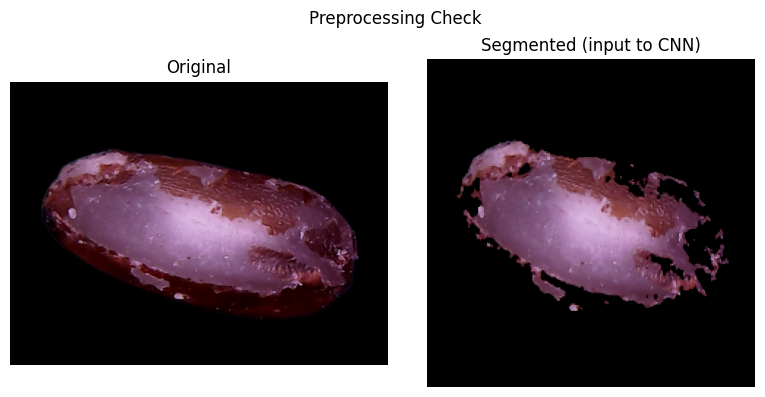

Segmented image shape: (224, 224, 3) | dtype: uint8


In [5]:
def segment_grain(image_path):
    """
    Segments the rice grain from black background.
    Returns uint8 RGB image [0-255] sized to IMG_SIZE.
    """
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f'Cannot read: {image_path}')

    # Grayscale + Otsu binarization
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, binary = cv2.threshold(gray, 0, 255,
                               cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Morphological cleanup
    kernel = np.ones((3, 3), np.uint8)
    cleaned = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=2)
    cleaned = cv2.medianBlur(cleaned, 5)

    # Apply mask to colour image
    mask3   = cv2.cvtColor(cleaned, cv2.COLOR_GRAY2BGR)
    segment = cv2.bitwise_and(img, mask3)

    # Resize and convert to RGB
    segment = cv2.resize(segment, IMG_SIZE)
    segment = cv2.cvtColor(segment, cv2.COLOR_BGR2RGB)
    return segment  # uint8 [0-255]


# Visualise preprocessing stages
sample = all_paths[0]
orig   = cv2.cvtColor(cv2.imread(sample), cv2.COLOR_BGR2RGB)
seg    = segment_grain(sample)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(orig); axes[0].set_title('Original'); axes[0].axis('off')
axes[1].imshow(seg);  axes[1].set_title('Segmented (input to CNN)'); axes[1].axis('off')
plt.suptitle('Preprocessing Check', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'preprocessing_check.png'), dpi=150)
plt.show()
print('Segmented image shape:', seg.shape, '| dtype:', seg.dtype)

## 5. Build Dataset

In [6]:
def build_dataset(paths, labels):
    X, y, failed = [], [], []
    for i, (p, l) in enumerate(zip(paths, labels)):
        try:
            X.append(segment_grain(p))
            y.append(l)
        except Exception as e:
            failed.append((p, str(e)))
        if (i + 1) % 500 == 0:
            print(f'  {i+1}/{len(paths)}')
    if failed:
        print(f'Failed: {len(failed)} images')
    return np.array(X, dtype=np.uint8), np.array(y, dtype=np.int64)

print('Building dataset (uint8)...')
X_all, y_all = build_dataset(all_paths, all_labels)
print(f'Done. Shape: {X_all.shape} | dtype: {X_all.dtype}')
print(f'Memory: {X_all.nbytes / 1e6:.0f} MB')

Building dataset (uint8)...
  500/8000
  1000/8000
  1500/8000
  2000/8000
  2500/8000
  3000/8000
  3500/8000
  4000/8000
  4500/8000
  5000/8000
  5500/8000
  6000/8000
  6500/8000
  7000/8000
  7500/8000
  8000/8000
Done. Shape: (8000, 224, 224, 3) | dtype: uint8
Memory: 1204 MB


## 6. Train / Val / Test Split

In [7]:
X_tmp,  X_test, y_tmp,  y_test  = train_test_split(
    X_all, y_all, test_size=0.15, stratify=y_all, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp,  y_tmp,  test_size=0.176, stratify=y_tmp,  random_state=SEED)

print(f'Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')
for name, lbls in [('Train',y_train),('Val',y_val),('Test',y_test)]:
    c = Counter(lbls)
    print(f'  {name}: {[c[i] for i in range(NUM_CLASSES)]}')

Train: 5603 | Val: 1197 | Test: 1200
  Train: [560, 561, 560, 560, 560, 561, 560, 560, 561, 560]
  Val: [120, 119, 120, 120, 120, 119, 120, 120, 119, 120]
  Test: [120, 120, 120, 120, 120, 120, 120, 120, 120, 120]


## 7. PyTorch Dataset & DataLoader

In [8]:
class RiceDataset(Dataset):
    """PyTorch dataset for rice grain images."""

    def __init__(self, images, labels, transform=None):
        self.images    = images    # uint8 numpy (N, H, W, 3)
        self.labels    = labels    # int64 numpy (N,)
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img   = self.images[idx]          # (H, W, 3) uint8
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label


def make_transforms(mean, std, input_size, train=True):
    """Return torchvision transforms for a specific model."""
    size = input_size if isinstance(input_size, int) else input_size[0]
    if train:
        return T.Compose([
            T.ToPILImage(),
            T.Resize((size, size)),
            T.RandomHorizontalFlip(),
            T.RandomVerticalFlip(),
            T.RandomRotation(45),
            T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
            T.RandomAffine(degrees=0, translate=(0.1, 0.1),
                           scale=(0.85, 1.15), shear=10),
            T.ToTensor(),
            T.Normalize(mean=mean, std=std),
        ])
    else:
        return T.Compose([
            T.ToPILImage(),
            T.Resize((size, size)),
            T.ToTensor(),
            T.Normalize(mean=mean, std=std),
        ])


def make_loaders(model_name):
    """Create train / val / test DataLoaders for a given model."""
    _, mean, std, inp_size = MODEL_CONFIGS[model_name]

    train_ds = RiceDataset(X_train, y_train,
                            transform=make_transforms(mean, std, inp_size, train=True))
    val_ds   = RiceDataset(X_val,   y_val,
                            transform=make_transforms(mean, std, inp_size, train=False))
    test_ds  = RiceDataset(X_test,  y_test,
                            transform=make_transforms(mean, std, inp_size, train=False))

    pin = DEVICE.type == 'cuda'
    train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=pin, drop_last=True)
    val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=pin)
    test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=pin)
    return train_dl, val_dl, test_dl

print('Dataset / DataLoader helpers ready.')

Dataset / DataLoader helpers ready.


## 8. Model Builder

In [ ]:
def build_model(model_name, num_classes):
    """
    Returns a torchvision/timm model adapted for `num_classes`.
    BatchNorm layers are kept in eval mode (frozen stats) as in the original.
    """
    arch = MODEL_CONFIGS[model_name][0]  # string key

    # ---- torchvision models ----
    if arch == 'efficientnet_b0':
        m = tv_models.efficientnet_b0(weights='IMAGENET1K_V1')
        in_feat = m.classifier[1].in_features
        m.classifier = nn.Sequential(
            nn.BatchNorm1d(in_feat),
            nn.Linear(in_feat, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    elif arch == 'mobilenet_v2':
        m = tv_models.mobilenet_v2(weights='IMAGENET1K_V1')
        in_feat = m.classifier[1].in_features
        m.classifier = nn.Sequential(
            nn.BatchNorm1d(in_feat),
            nn.Linear(in_feat, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    elif arch == 'vgg16':
        m = tv_models.vgg16(weights='IMAGENET1K_V1')
        in_feat = m.classifier[0].in_features
        m.classifier = nn.Sequential(
            nn.Linear(in_feat, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    elif arch == 'inception_v3':
        m = tv_models.inception_v3(weights='IMAGENET1K_V1', aux_logits=True)
        # Replace both main and aux classifiers
        in_feat = m.fc.in_features
        m.fc = nn.Sequential(
            nn.BatchNorm1d(in_feat),
            nn.Linear(in_feat, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
        m.AuxLogits.fc = nn.Linear(m.AuxLogits.fc.in_features, num_classes)

    elif HAS_TIMM and arch in ('xception', 'inception_resnet_v2'):
        m = timm.create_model(arch, pretrained=True, num_classes=0, global_pool='avg')
        in_feat = m.num_features
        m.head = nn.Sequential()
        # Wrap in a container so we can attach our head
        class TimmWrapper(nn.Module):
            def __init__(self, backbone, head):
                super().__init__()
                self.backbone = backbone
                self.head     = head
            def forward(self, x):
                return self.head(self.backbone(x))
        head = nn.Sequential(
            nn.BatchNorm1d(in_feat),
            nn.Linear(in_feat, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
        m = TimmWrapper(m, head)
    else:
        raise ValueError(f'Unknown arch: {arch}')

    # Freeze BatchNorm running stats (keep BN in eval mode during forward)
    # This mirrors the Keras `layer.trainable = False` on BN layers.
    def freeze_bn(module):
        for mod in module.modules():
            if isinstance(mod, (nn.BatchNorm2d, nn.BatchNorm1d)):
                mod.eval()
                for p in mod.parameters():
                    p.requires_grad_(False)

    m.apply(freeze_bn)
    # But allow the NEW head's BN to train
    # (they don't have pretrained stats)
    if hasattr(m, 'classifier'):
        for mod in m.classifier.modules():
            if isinstance(mod, nn.BatchNorm1d):
                mod.train()
                for p in mod.parameters():
                    p.requires_grad_(True)
    if hasattr(m, 'fc'):
        for mod in m.fc.modules():
            if isinstance(mod, nn.BatchNorm1d):
                mod.train()
                for p in mod.parameters():
                    p.requires_grad_(True)
    if hasattr(m, 'head'):
        for mod in m.head.modules():
            if isinstance(mod, nn.BatchNorm1d):
                mod.train()
                for p in mod.parameters():
                    p.requires_grad_(True)

    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'  Trainable params: {trainable:,}')
    return m

print('Model builder ready.')

Model builder ready.


## 9. Training Loop

In [10]:
def train_model(model_name):
    print(f'\n{"="*55}')
    print(f'  {model_name}')
    print(f'{"="*55}')

    train_dl, val_dl, _ = make_loaders(model_name)
    model = build_model(model_name, NUM_CLASSES).to(DEVICE)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),
                           lr=LR, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=0.5, patience=5, min_lr=1e-7, verbose=True)

    # Mixed-precision scaler (disabled on CPU)
    use_amp = DEVICE.type == 'cuda'
    scaler  = GradScaler(enabled=use_amp)

    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_val_acc  = 0.0
    patience_cnt  = 0
    PATIENCE      = 12
    best_path     = os.path.join(OUTPUT_DIR, 'models', f'{model_name}_best.pt')

    is_inception = MODEL_CONFIGS[model_name][0] == 'inception_v3'

    for epoch in range(1, EPOCHS + 1):
        # ---- Training ----
        model.train()
        # Keep pretrained BN in eval mode
        for mod in model.modules():
            if isinstance(mod, nn.BatchNorm2d):
                mod.eval()

        train_loss = train_correct = train_total = 0
        for imgs, labels in train_dl:
            imgs   = imgs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad()
            with autocast(enabled=use_amp):
                if is_inception:
                    outputs, aux = model(imgs)   # InceptionV3 returns (main, aux)
                    loss = criterion(outputs, labels) + 0.4 * criterion(aux, labels)
                else:
                    outputs = model(imgs)
                    loss    = criterion(outputs, labels)

            scaler.scale(loss).backward()
            # Gradient clipping (like clipnorm=1.0 in Keras Adam)
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                filter(lambda p: p.requires_grad, model.parameters()), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            train_loss    += loss.item() * imgs.size(0)
            preds          = outputs.argmax(dim=1)
            train_correct += (preds == labels).sum().item()
            train_total   += imgs.size(0)

        epoch_loss = train_loss / train_total
        epoch_acc  = train_correct / train_total

        # ---- Validation ----
        model.eval()
        val_loss = val_correct = val_total = 0
        with torch.no_grad():
            for imgs, labels in val_dl:
                imgs   = imgs.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)
                with autocast(enabled=use_amp):
                    outputs = model(imgs)
                    if isinstance(outputs, tuple):   # safety
                        outputs = outputs[0]
                    loss = criterion(outputs, labels)
                val_loss    += loss.item() * imgs.size(0)
                preds        = outputs.argmax(dim=1)
                val_correct += (preds == labels).sum().item()
                val_total   += imgs.size(0)

        epoch_val_loss = val_loss / val_total
        epoch_val_acc  = val_correct / val_total

        history['loss'].append(epoch_loss)
        history['accuracy'].append(epoch_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_accuracy'].append(epoch_val_acc)

        print(f'Epoch {epoch:3d}/{EPOCHS}  '
              f'loss={epoch_loss:.4f}  acc={epoch_acc:.4f}  '
              f'val_loss={epoch_val_loss:.4f}  val_acc={epoch_val_acc:.4f}')

        scheduler.step(epoch_val_acc)

        # Early stopping
        if epoch_val_acc > best_val_acc:
            best_val_acc = epoch_val_acc
            torch.save(model.state_dict(), best_path)
            print(f'  → saved best model (val_acc={best_val_acc:.4f})')
            patience_cnt = 0
        else:
            patience_cnt += 1
            if patience_cnt >= PATIENCE:
                print(f'  Early stop at epoch {epoch} (no improvement for {PATIENCE} epochs)')
                break

    # Restore best weights
    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    print(f'  Best val_accuracy: {best_val_acc:.4f}')
    torch.save(model.state_dict(), os.path.join(OUTPUT_DIR, 'models', f'{model_name}_final.pt'))
    return model, history


print('Trainer ready.')

Trainer ready.


## 10. Train EfficientNetB0 First
Confirm the pipeline works before running all models.


  EfficientNetB0
  Trainable params: 4,757,862
Epoch   1/20  loss=0.9789  acc=0.7064  val_loss=0.2995  val_acc=0.8805
  → saved best model (val_acc=0.8805)
Epoch   2/20  loss=0.3146  acc=0.8857  val_loss=0.2091  val_acc=0.9298
  → saved best model (val_acc=0.9298)
Epoch   3/20  loss=0.2563  acc=0.9104  val_loss=0.2109  val_acc=0.9215
Epoch   4/20  loss=0.1993  acc=0.9291  val_loss=0.1672  val_acc=0.9482
  → saved best model (val_acc=0.9482)
Epoch   5/20  loss=0.1748  acc=0.9398  val_loss=0.1298  val_acc=0.9482
Epoch   6/20  loss=0.1599  acc=0.9459  val_loss=0.1953  val_acc=0.9332
Epoch   7/20  loss=0.1603  acc=0.9445  val_loss=0.2192  val_acc=0.9206
Epoch   8/20  loss=0.1313  acc=0.9537  val_loss=0.0867  val_acc=0.9691
  → saved best model (val_acc=0.9691)
Epoch   9/20  loss=0.1289  acc=0.9559  val_loss=0.4391  val_acc=0.8964
Epoch  10/20  loss=0.1247  acc=0.9554  val_loss=0.0745  val_acc=0.9716
  → saved best model (val_acc=0.9716)
Epoch  11/20  loss=0.1080  acc=0.9636  val_loss=0.07

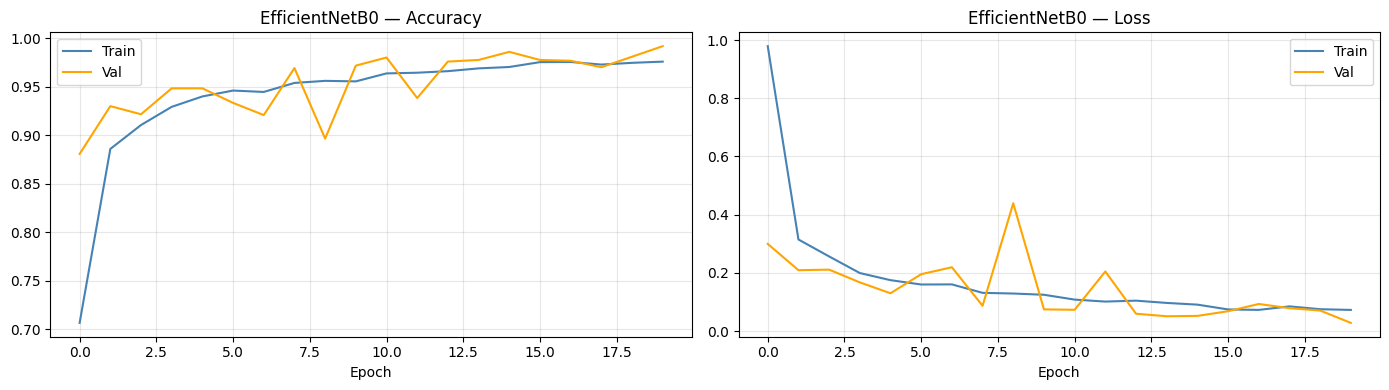

Best val_accuracy: 0.9916457811194653


In [11]:
trained_models = {}
histories      = {}

model, hist = train_model('EfficientNetB0')
trained_models['EfficientNetB0'] = model
histories['EfficientNetB0']      = hist

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
h = hist
axes[0].plot(h['accuracy'],     label='Train', color='steelblue')
axes[0].plot(h['val_accuracy'], label='Val',   color='orange')
axes[0].set_title('EfficientNetB0 — Accuracy')
axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(h['loss'],     label='Train', color='steelblue')
axes[1].plot(h['val_loss'], label='Val',   color='orange')
axes[1].set_title('EfficientNetB0 — Loss')
axes[1].set_xlabel('Epoch'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'efficientnet_curves.png'), dpi=150)
plt.show()
print('Best val_accuracy:', max(hist['val_accuracy']))

## 11. Train All Remaining Models

In [12]:
remaining = [n for n in MODEL_CONFIGS if n != 'EfficientNetB0']

for name in remaining:
    model, hist = train_model(name)
    trained_models[name] = model
    histories[name]      = hist

print('\nAll models trained. Best val_accuracy per model:')
for name, h in histories.items():
    print(f'  {name}: {max(h["val_accuracy"]):.4f}')


  MobileNetV2
  Trainable params: 2,982,090
Epoch   1/20  loss=0.9705  acc=0.6713  val_loss=0.4249  val_acc=0.8045
  → saved best model (val_acc=0.8045)
Epoch   2/20  loss=0.3627  acc=0.8686  val_loss=0.5176  val_acc=0.8463
  → saved best model (val_acc=0.8463)
Epoch   3/20  loss=0.3128  acc=0.8870  val_loss=0.2707  val_acc=0.9073
  → saved best model (val_acc=0.9073)
Epoch   4/20  loss=0.2622  acc=0.9061  val_loss=0.4196  val_acc=0.8438
Epoch   5/20  loss=0.2176  acc=0.9221  val_loss=0.3535  val_acc=0.8981
Epoch   6/20  loss=0.2179  acc=0.9205  val_loss=0.2965  val_acc=0.8997
Epoch   7/20  loss=0.1930  acc=0.9291  val_loss=0.1537  val_acc=0.9407
  → saved best model (val_acc=0.9407)
Epoch   8/20  loss=0.1876  acc=0.9334  val_loss=0.5559  val_acc=0.8438
Epoch   9/20  loss=0.1710  acc=0.9411  val_loss=0.2321  val_acc=0.9231
Epoch  10/20  loss=0.1668  acc=0.9437  val_loss=0.2077  val_acc=0.9215
Epoch  11/20  loss=0.1503  acc=0.9468  val_loss=0.1741  val_acc=0.9323
Epoch  12/20  loss=0.1

  Trainable params: 55,169,834
Epoch   1/20  loss=0.8587  acc=0.7200  val_loss=0.6017  val_acc=0.7686
  → saved best model (val_acc=0.7686)
Epoch   2/20  loss=0.3098  acc=0.8891  val_loss=0.2136  val_acc=0.9215
  → saved best model (val_acc=0.9215)
Epoch   3/20  loss=0.2238  acc=0.9204  val_loss=0.2003  val_acc=0.9365
  → saved best model (val_acc=0.9365)
Epoch   4/20  loss=0.1799  acc=0.9391  val_loss=0.1272  val_acc=0.9457
  → saved best model (val_acc=0.9457)
Epoch   5/20  loss=0.1422  acc=0.9473  val_loss=0.0929  val_acc=0.9641
  → saved best model (val_acc=0.9641)
Epoch   6/20  loss=0.1301  acc=0.9541  val_loss=0.1959  val_acc=0.9449
Epoch   7/20  loss=0.1317  acc=0.9554  val_loss=0.3106  val_acc=0.9098
Epoch   8/20  loss=0.1340  acc=0.9541  val_loss=0.1097  val_acc=0.9641
Epoch   9/20  loss=0.1004  acc=0.9657  val_loss=0.4491  val_acc=0.8889
Epoch  10/20  loss=0.1099  acc=0.9654  val_loss=0.3589  val_acc=0.8830
Epoch  11/20  loss=0.0847  acc=0.9702  val_loss=0.0985  val_acc=0.969

## 12. Training Curves — All Models

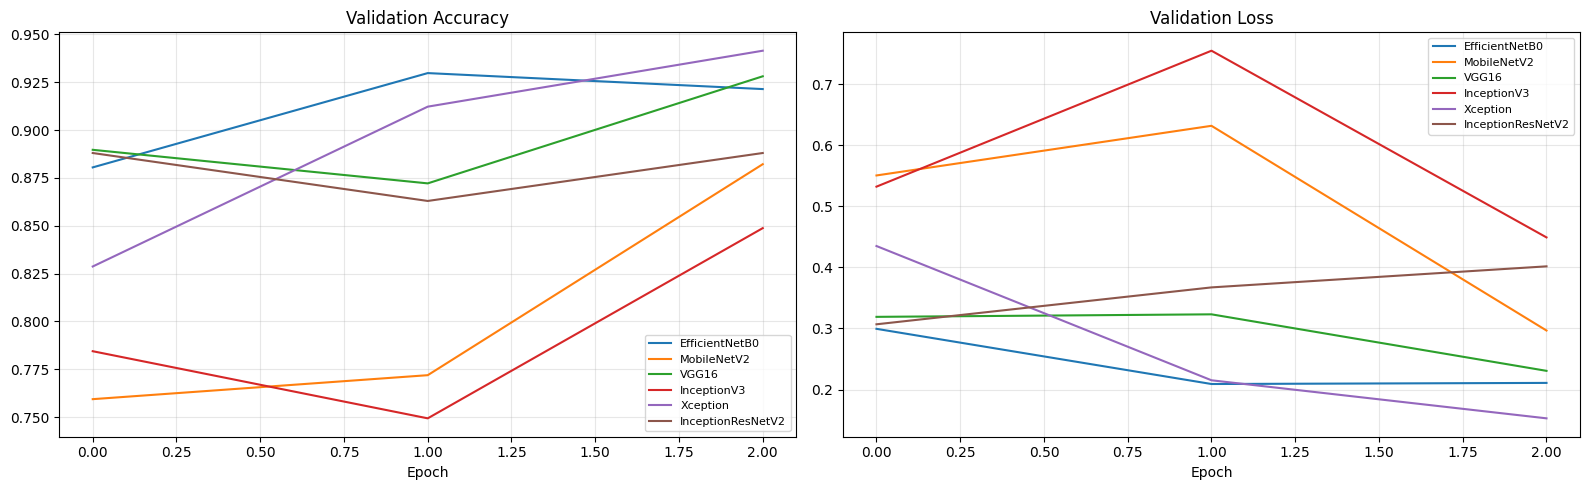

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for name, h in histories.items():
    axes[0].plot(h['val_accuracy'], label=name)
    axes[1].plot(h['val_loss'],     label=name)
for ax, title in zip(axes, ['Validation Accuracy','Validation Loss']):
    ax.set_title(title, fontsize=12); ax.set_xlabel('Epoch')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'all_training_curves.png'), dpi=150)
plt.show()

## 13. Evaluate on Test Set


-- EfficientNetB0  |  Test Accuracy: 0.9142 --
               precision    recall  f1-score   support

         Aush       1.00      0.97      0.98       120
        BR-28       0.81      0.87      0.84       120
        BR-29       0.83      0.99      0.90       120
        Beroi       0.98      1.00      0.99       120
    Chinigura       1.00      0.88      0.94       120
    Ghee Bhog       0.90      0.92      0.91       120
 Katari Najir       0.87      0.81      0.84       120
Katari Siddho       0.98      0.76      0.85       120
      Miniket       0.95      1.00      0.98       120
       Swarna       0.87      0.95      0.91       120

     accuracy                           0.91      1200
    macro avg       0.92      0.91      0.91      1200
 weighted avg       0.92      0.91      0.91      1200



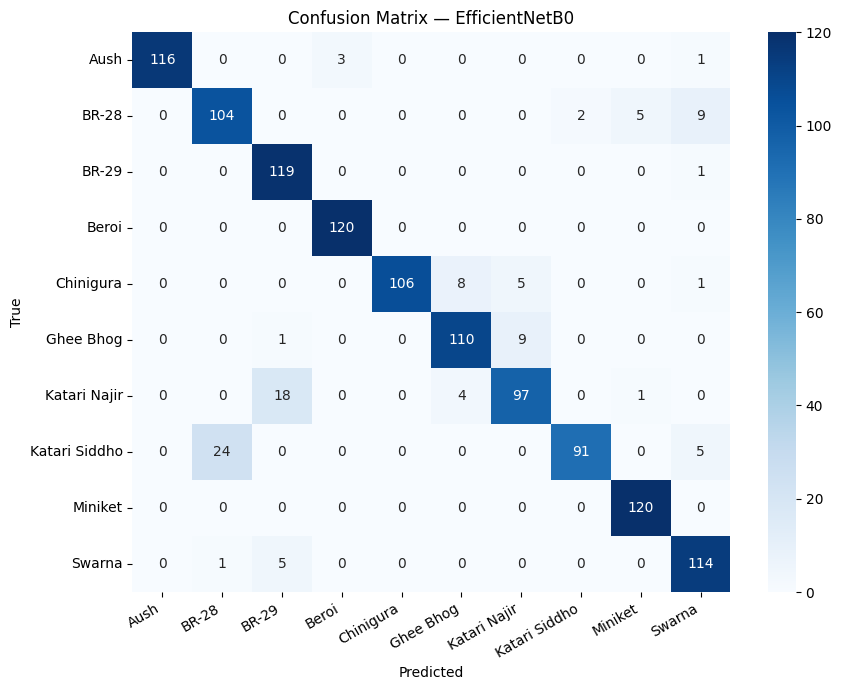


-- MobileNetV2  |  Test Accuracy: 0.8708 --
               precision    recall  f1-score   support

         Aush       1.00      0.99      1.00       120
        BR-28       0.56      0.82      0.66       120
        BR-29       0.92      0.88      0.90       120
        Beroi       1.00      1.00      1.00       120
    Chinigura       0.98      0.97      0.98       120
    Ghee Bhog       0.95      0.87      0.91       120
 Katari Najir       0.78      0.98      0.87       120
Katari Siddho       1.00      0.33      0.50       120
      Miniket       0.87      1.00      0.93       120
       Swarna       0.90      0.87      0.89       120

     accuracy                           0.87      1200
    macro avg       0.90      0.87      0.86      1200
 weighted avg       0.90      0.87      0.86      1200



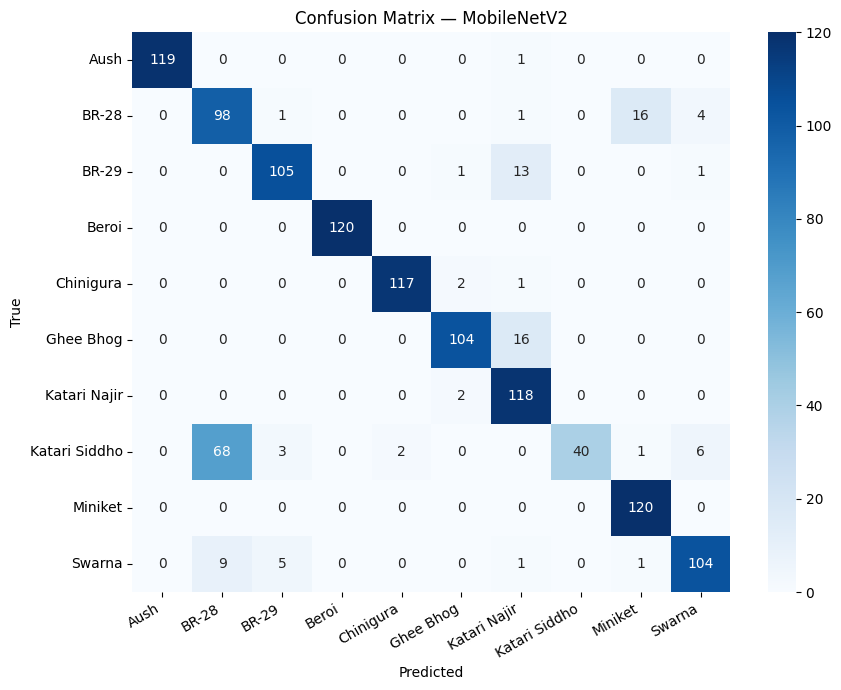


-- VGG16  |  Test Accuracy: 0.9258 --
               precision    recall  f1-score   support

         Aush       0.99      1.00      1.00       120
        BR-28       0.91      0.88      0.89       120
        BR-29       0.79      0.98      0.87       120
        Beroi       1.00      0.98      0.99       120
    Chinigura       0.99      0.97      0.98       120
    Ghee Bhog       0.85      0.93      0.88       120
 Katari Najir       0.94      0.67      0.78       120
Katari Siddho       0.95      0.92      0.93       120
      Miniket       0.99      1.00      1.00       120
       Swarna       0.90      0.93      0.92       120

     accuracy                           0.93      1200
    macro avg       0.93      0.93      0.92      1200
 weighted avg       0.93      0.93      0.92      1200



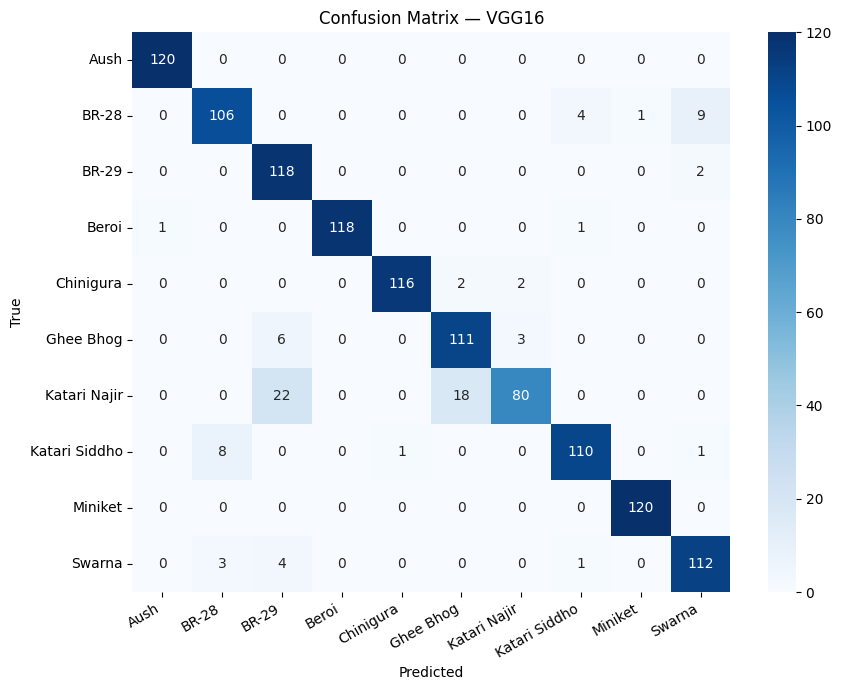


-- InceptionV3  |  Test Accuracy: 0.8467 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       120
        BR-28       0.62      0.75      0.68       120
        BR-29       0.94      0.85      0.89       120
        Beroi       1.00      1.00      1.00       120
    Chinigura       1.00      0.75      0.86       120
    Ghee Bhog       0.63      0.99      0.77       120
 Katari Najir       0.92      0.68      0.78       120
Katari Siddho       0.97      0.91      0.94       120
      Miniket       1.00      0.57      0.72       120
       Swarna       0.74      0.97      0.84       120

     accuracy                           0.85      1200
    macro avg       0.88      0.85      0.85      1200
 weighted avg       0.88      0.85      0.85      1200



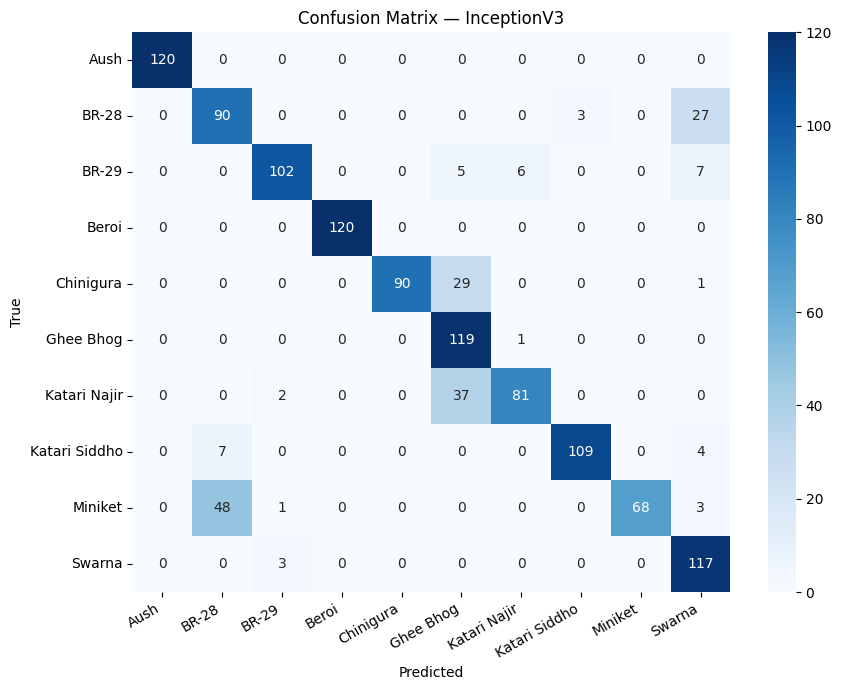


-- Xception  |  Test Accuracy: 0.9308 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       120
        BR-28       0.91      0.83      0.87       120
        BR-29       0.98      0.88      0.93       120
        Beroi       1.00      1.00      1.00       120
    Chinigura       1.00      0.97      0.99       120
    Ghee Bhog       0.98      0.74      0.84       120
 Katari Najir       0.72      1.00      0.84       120
Katari Siddho       0.95      0.97      0.96       120
      Miniket       0.90      1.00      0.95       120
       Swarna       0.96      0.92      0.94       120

     accuracy                           0.93      1200
    macro avg       0.94      0.93      0.93      1200
 weighted avg       0.94      0.93      0.93      1200



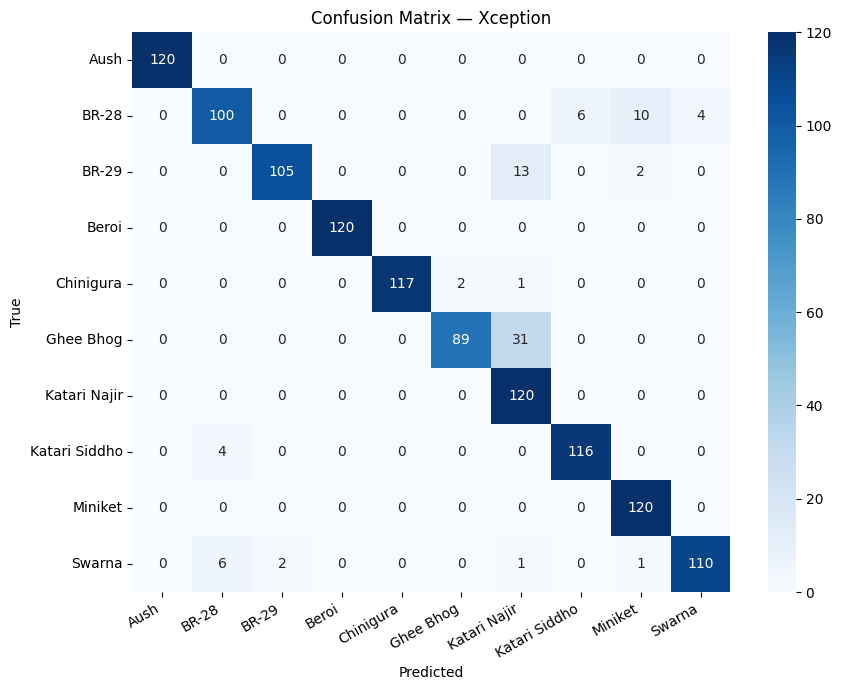


-- InceptionResNetV2  |  Test Accuracy: 0.8775 --
               precision    recall  f1-score   support

         Aush       1.00      0.98      0.99       120
        BR-28       0.61      0.96      0.75       120
        BR-29       0.96      0.79      0.87       120
        Beroi       0.98      1.00      0.99       120
    Chinigura       0.86      1.00      0.92       120
    Ghee Bhog       1.00      0.72      0.84       120
 Katari Najir       0.75      0.95      0.84       120
Katari Siddho       0.92      0.61      0.73       120
      Miniket       0.98      1.00      0.99       120
       Swarna       0.98      0.76      0.85       120

     accuracy                           0.88      1200
    macro avg       0.90      0.88      0.88      1200
 weighted avg       0.90      0.88      0.88      1200



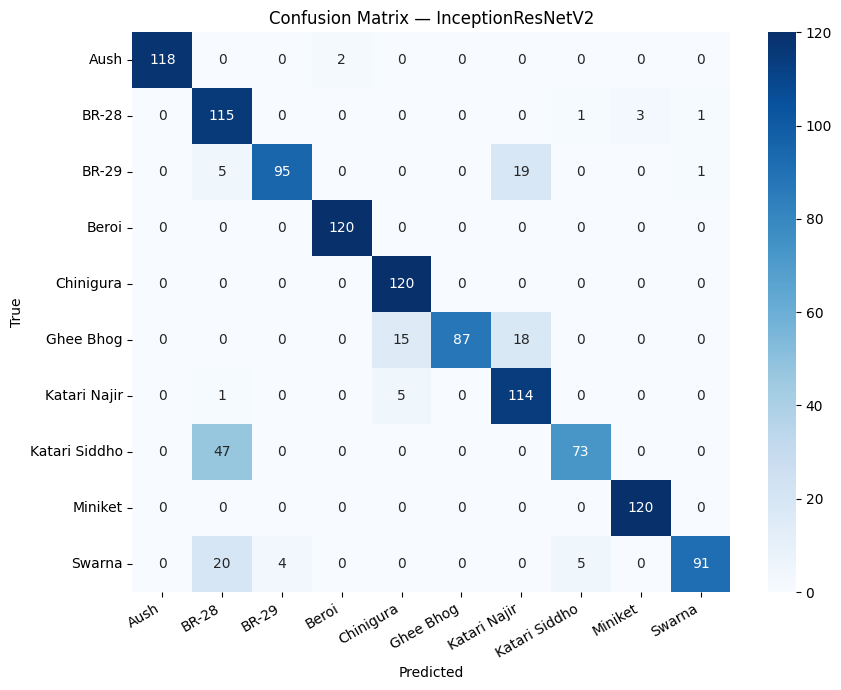

In [14]:
all_reports = {}
all_probas  = {}

def evaluate(model, model_name):
    _, val_dl_unused, test_dl = make_loaders(model_name)

    model.eval()
    all_proba, all_preds, all_true = [], [], []
    with torch.no_grad():
        for imgs, labels in test_dl:
            imgs = imgs.to(DEVICE, non_blocking=True)
            outputs = model(imgs)
            if isinstance(outputs, tuple):
                outputs = outputs[0]
            proba = torch.softmax(outputs, dim=1).cpu().numpy()
            all_proba.append(proba)
            all_preds.append(proba.argmax(axis=1))
            all_true.append(labels.numpy())

    proba  = np.vstack(all_proba)
    y_pred = np.concatenate(all_preds)
    y_true = np.concatenate(all_true)

    rep = classification_report(
        y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)

    print(f'\n-- {model_name}  |  Test Accuracy: {rep["accuracy"]:.4f} --')
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

    cm_arr = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(cm_arr, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f'Confusion Matrix — {model_name}', fontsize=12)
    ax.set_ylabel('True'); ax.set_xlabel('Predicted')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'cm_{model_name}.png'), dpi=150)
    plt.show()
    return rep, proba

for name, model in trained_models.items():
    rep, proba = evaluate(model, name)
    all_reports[name] = rep
    all_probas[name]  = proba

## 14. Ensemble — Hard / Soft / Weighted Voting

Weights: {'EfficientNetB0': np.float64(0.1716), 'MobileNetV2': np.float64(0.1628), 'VGG16': np.float64(0.1713), 'InceptionV3': np.float64(0.1566), 'Xception': np.float64(0.1738), 'InceptionResNetV2': np.float64(0.1639)}

-- Hard Voting  |  Accuracy: 0.9542 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       120
        BR-28       0.84      0.93      0.88       120
        BR-29       0.96      0.96      0.96       120
        Beroi       1.00      1.00      1.00       120
    Chinigura       1.00      0.97      0.99       120
    Ghee Bhog       0.95      0.93      0.94       120
 Katari Najir       0.91      0.97      0.94       120
Katari Siddho       0.98      0.83      0.90       120
      Miniket       0.98      1.00      0.99       120
       Swarna       0.94      0.96      0.95       120

     accuracy                           0.95      1200
    macro avg       0.96      0.95      0.95      1200
 weighted avg       0.9

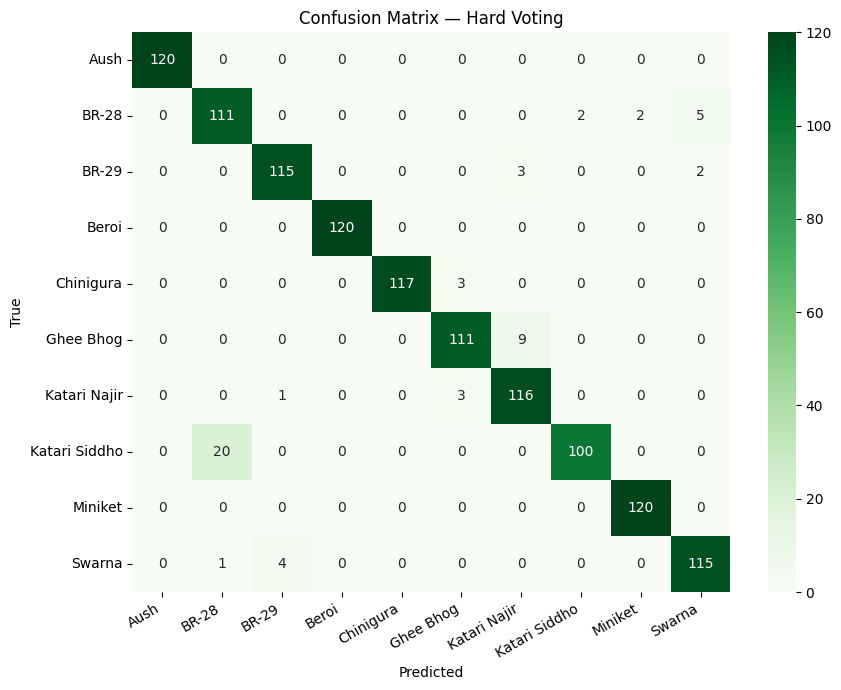


-- Soft Voting  |  Accuracy: 0.9625 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       120
        BR-28       0.92      0.89      0.91       120
        BR-29       0.96      0.97      0.96       120
        Beroi       1.00      1.00      1.00       120
    Chinigura       1.00      0.97      0.99       120
    Ghee Bhog       0.95      0.93      0.94       120
 Katari Najir       0.91      0.97      0.94       120
Katari Siddho       0.98      0.93      0.95       120
      Miniket       0.96      1.00      0.98       120
       Swarna       0.94      0.97      0.95       120

     accuracy                           0.96      1200
    macro avg       0.96      0.96      0.96      1200
 weighted avg       0.96      0.96      0.96      1200



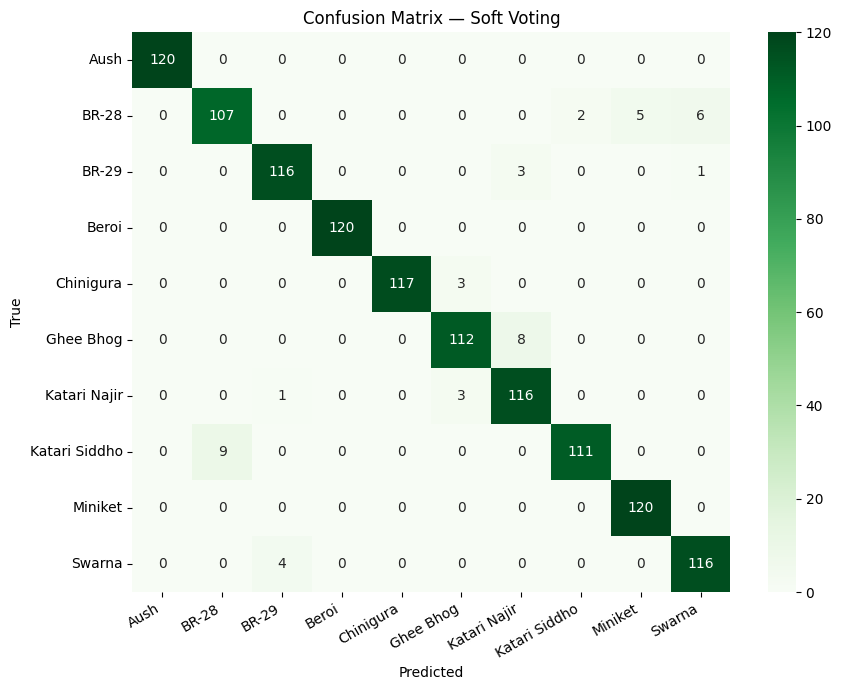


-- Weighted Voting  |  Accuracy: 0.9617 --
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00       120
        BR-28       0.92      0.89      0.91       120
        BR-29       0.96      0.97      0.96       120
        Beroi       1.00      1.00      1.00       120
    Chinigura       1.00      0.97      0.99       120
    Ghee Bhog       0.95      0.93      0.94       120
 Katari Najir       0.91      0.97      0.94       120
Katari Siddho       0.98      0.93      0.95       120
      Miniket       0.96      1.00      0.98       120
       Swarna       0.94      0.97      0.95       120

     accuracy                           0.96      1200
    macro avg       0.96      0.96      0.96      1200
 weighted avg       0.96      0.96      0.96      1200



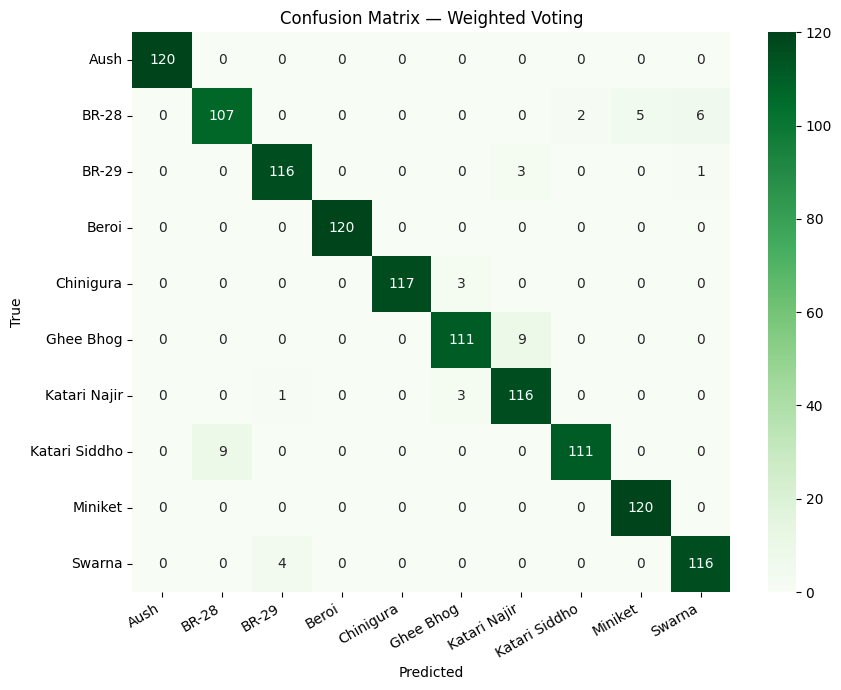

In [15]:
# Re-collect ground truth from test set (consistent order)
y_test_arr = np.concatenate([
    np.array([lbl for _, lbl in make_loaders(list(trained_models.keys())[0])[2].dataset])
])

preds_stack   = np.array([np.argmax(p, axis=1) for p in all_probas.values()])
hard_preds, _ = stats.mode(preds_stack, axis=0)
hard_preds    = hard_preds.flatten()

soft_avg   = np.mean(list(all_probas.values()), axis=0)
soft_preds = np.argmax(soft_avg, axis=1)

val_accs = np.array([max(histories[n]['val_accuracy']) for n in trained_models])
weights_ens = val_accs / val_accs.sum()
print('Weights:', dict(zip(trained_models.keys(), weights_ens.round(4))))

weighted_avg   = np.average(list(all_probas.values()), axis=0, weights=weights_ens)
weighted_preds = np.argmax(weighted_avg, axis=1)

for ens_name, preds, proba in [
    ('Hard Voting',     hard_preds,     None),
    ('Soft Voting',     soft_preds,     soft_avg),
    ('Weighted Voting', weighted_preds, weighted_avg),
]:
    rep = classification_report(
        y_test, preds, target_names=CLASS_NAMES, output_dict=True)
    all_reports[ens_name] = rep
    if proba is not None: all_probas[ens_name] = proba
    print(f'\n-- {ens_name}  |  Accuracy: {rep["accuracy"]:.4f} --')
    print(classification_report(y_test, preds, target_names=CLASS_NAMES))
    cm_arr = confusion_matrix(y_test, preds)
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(cm_arr, annot=True, fmt='d', cmap='Greens',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    safe = ens_name.replace(' ','_')
    ax.set_title(f'Confusion Matrix — {ens_name}', fontsize=12)
    ax.set_ylabel('True'); ax.set_xlabel('Predicted')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'cm_{safe}.png'), dpi=150)
    plt.show()

## 15. ROC-AUC Curves

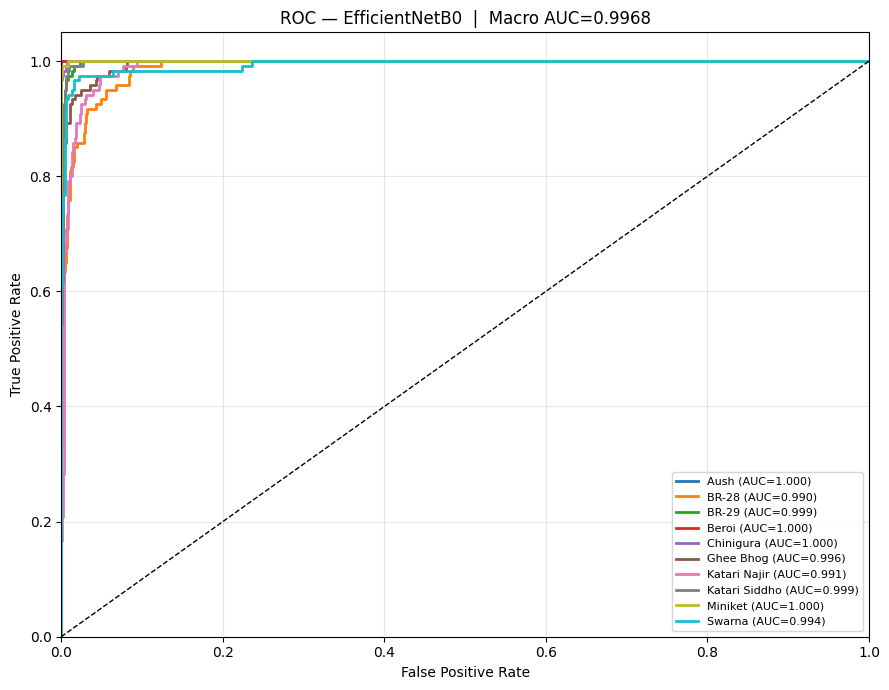

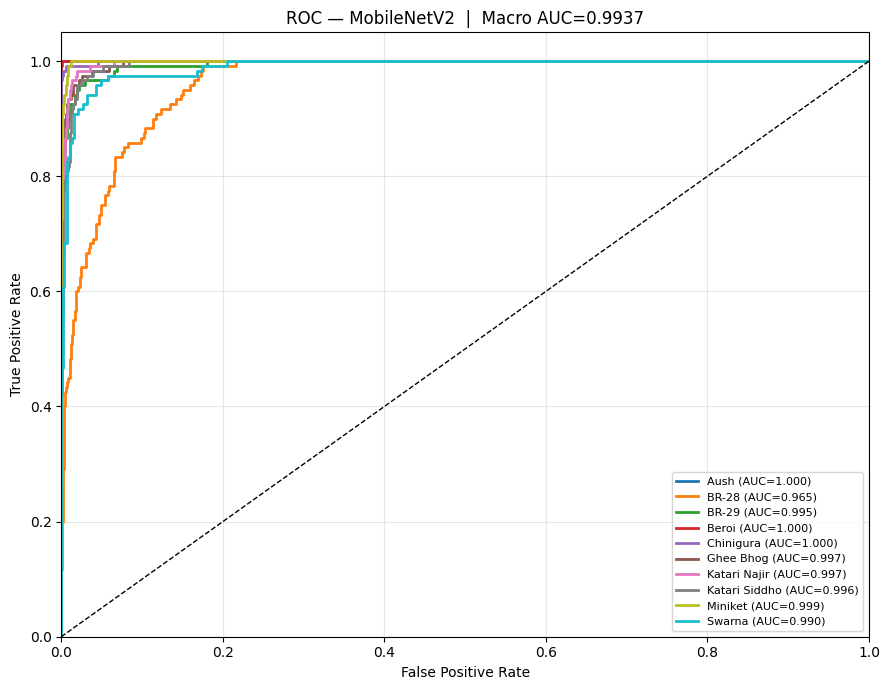

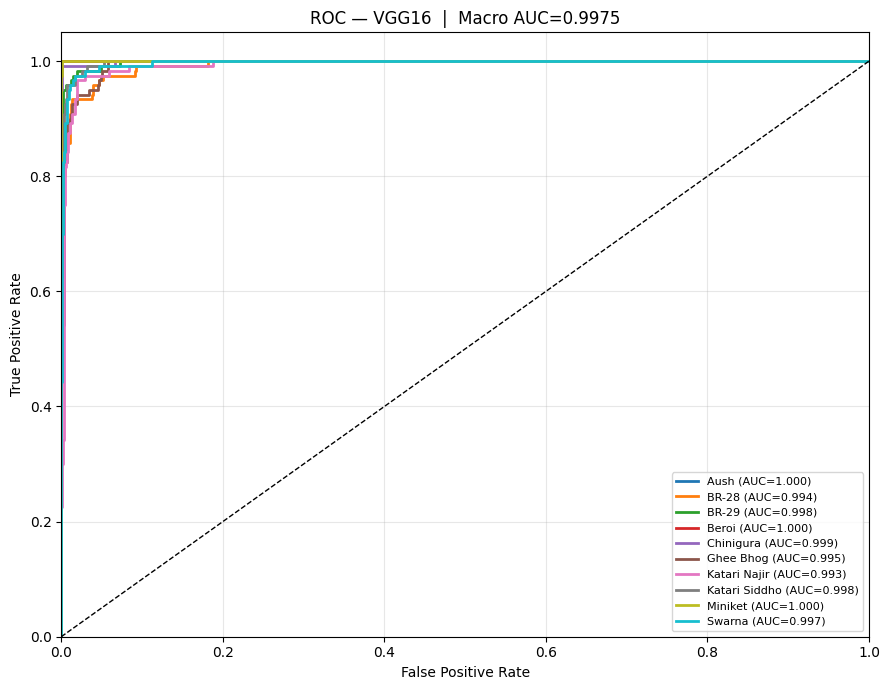

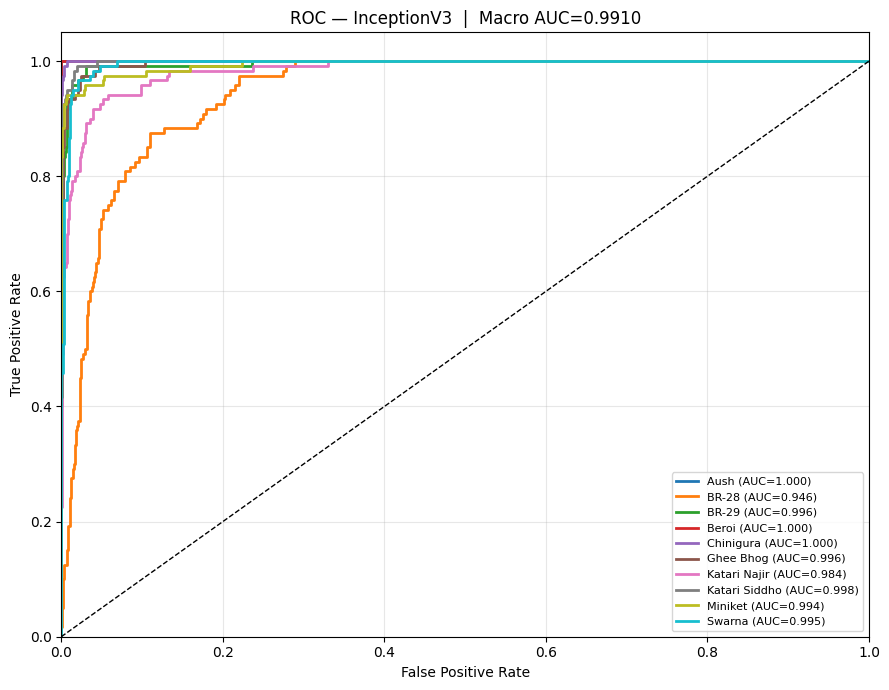

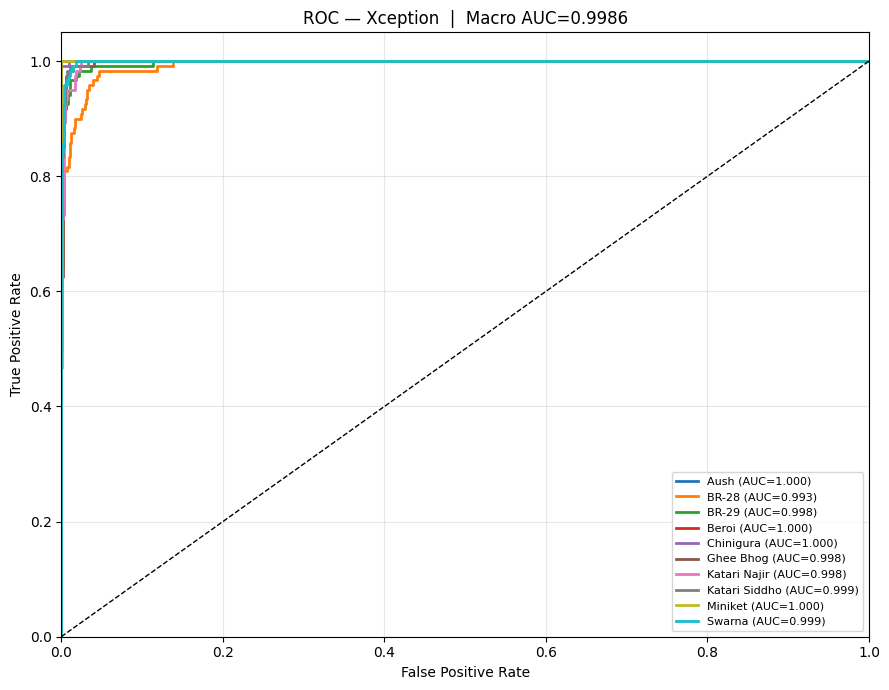

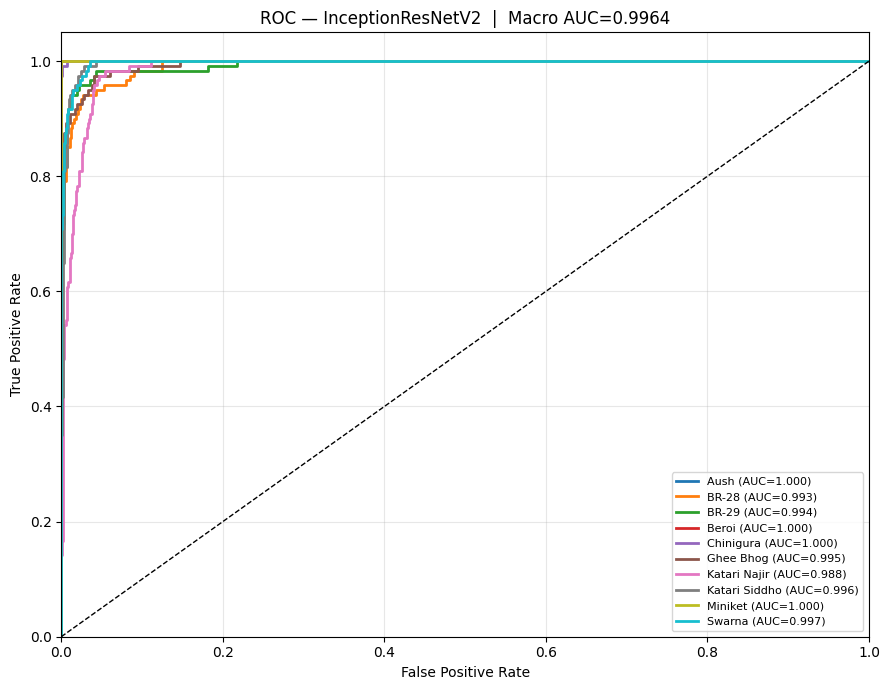

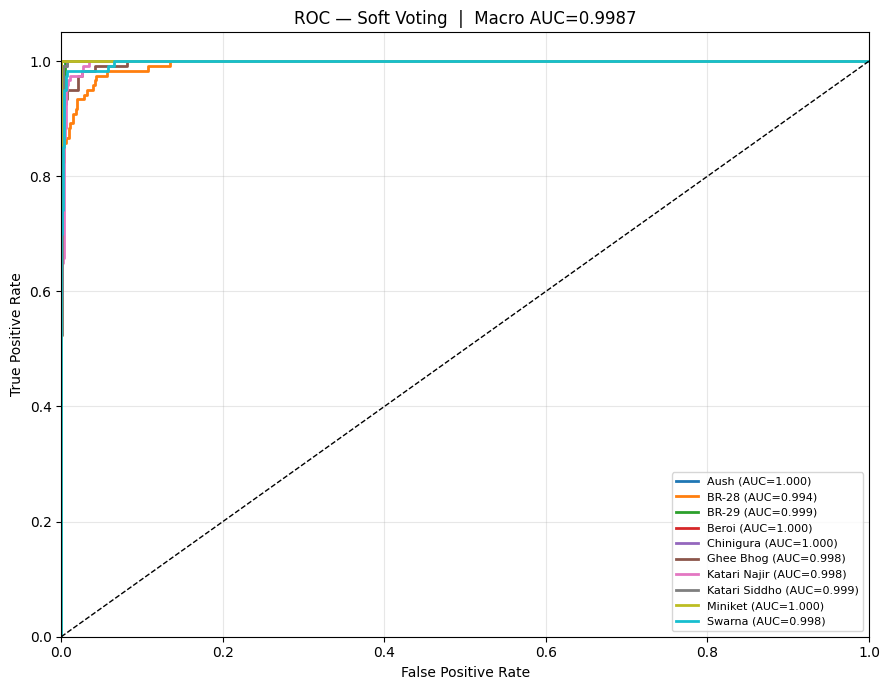

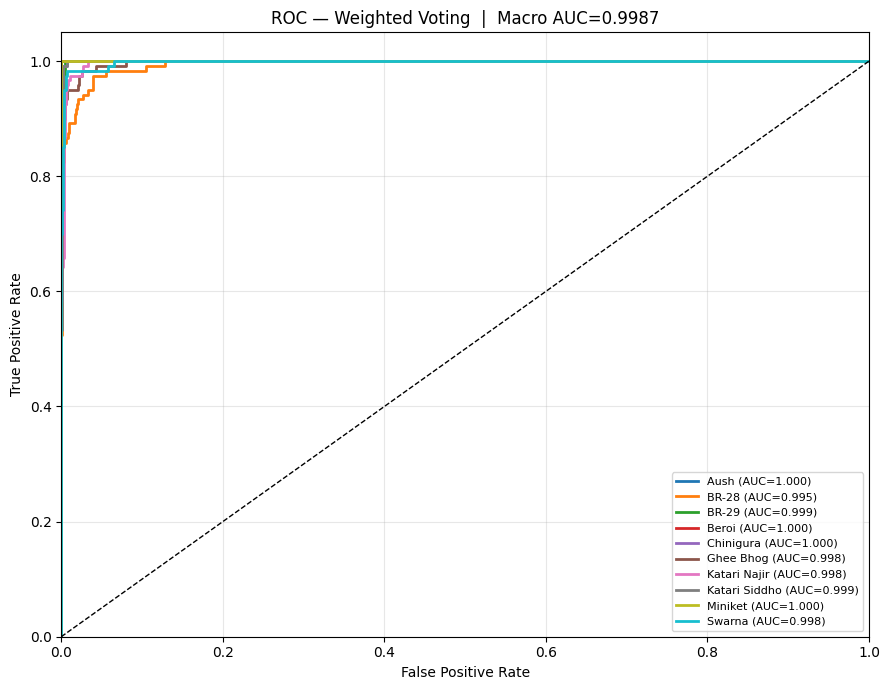

In [16]:
def plot_roc(y_true, y_proba, title):
    y_bin  = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    colors = plt.cm.tab10(np.linspace(0, 1, NUM_CLASSES))
    fig, ax = plt.subplots(figsize=(9, 7))
    aucs = []
    for i, (cls, col) in enumerate(zip(CLASS_NAMES, colors)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
        a = auc(fpr, tpr); aucs.append(a)
        ax.plot(fpr, tpr, color=col, lw=2, label=f'{cls} (AUC={a:.3f})')
    ax.plot([0,1],[0,1],'k--',lw=1)
    ax.set_xlim([0,1]); ax.set_ylim([0,1.05])
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'ROC — {title}  |  Macro AUC={np.mean(aucs):.4f}')
    ax.legend(loc='lower right', fontsize=8); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    safe = title.replace(' ','_').replace('(','').replace(')','').replace('/','_')
    plt.savefig(os.path.join(OUTPUT_DIR, f'roc_{safe}.png'), dpi=150)
    plt.show()
    all_reports[title]['macro_auc'] = round(float(np.mean(aucs)), 4)

for name, proba in all_probas.items():
    if name in all_reports:
        plot_roc(y_test, proba, name)

## 16. Grad-CAM

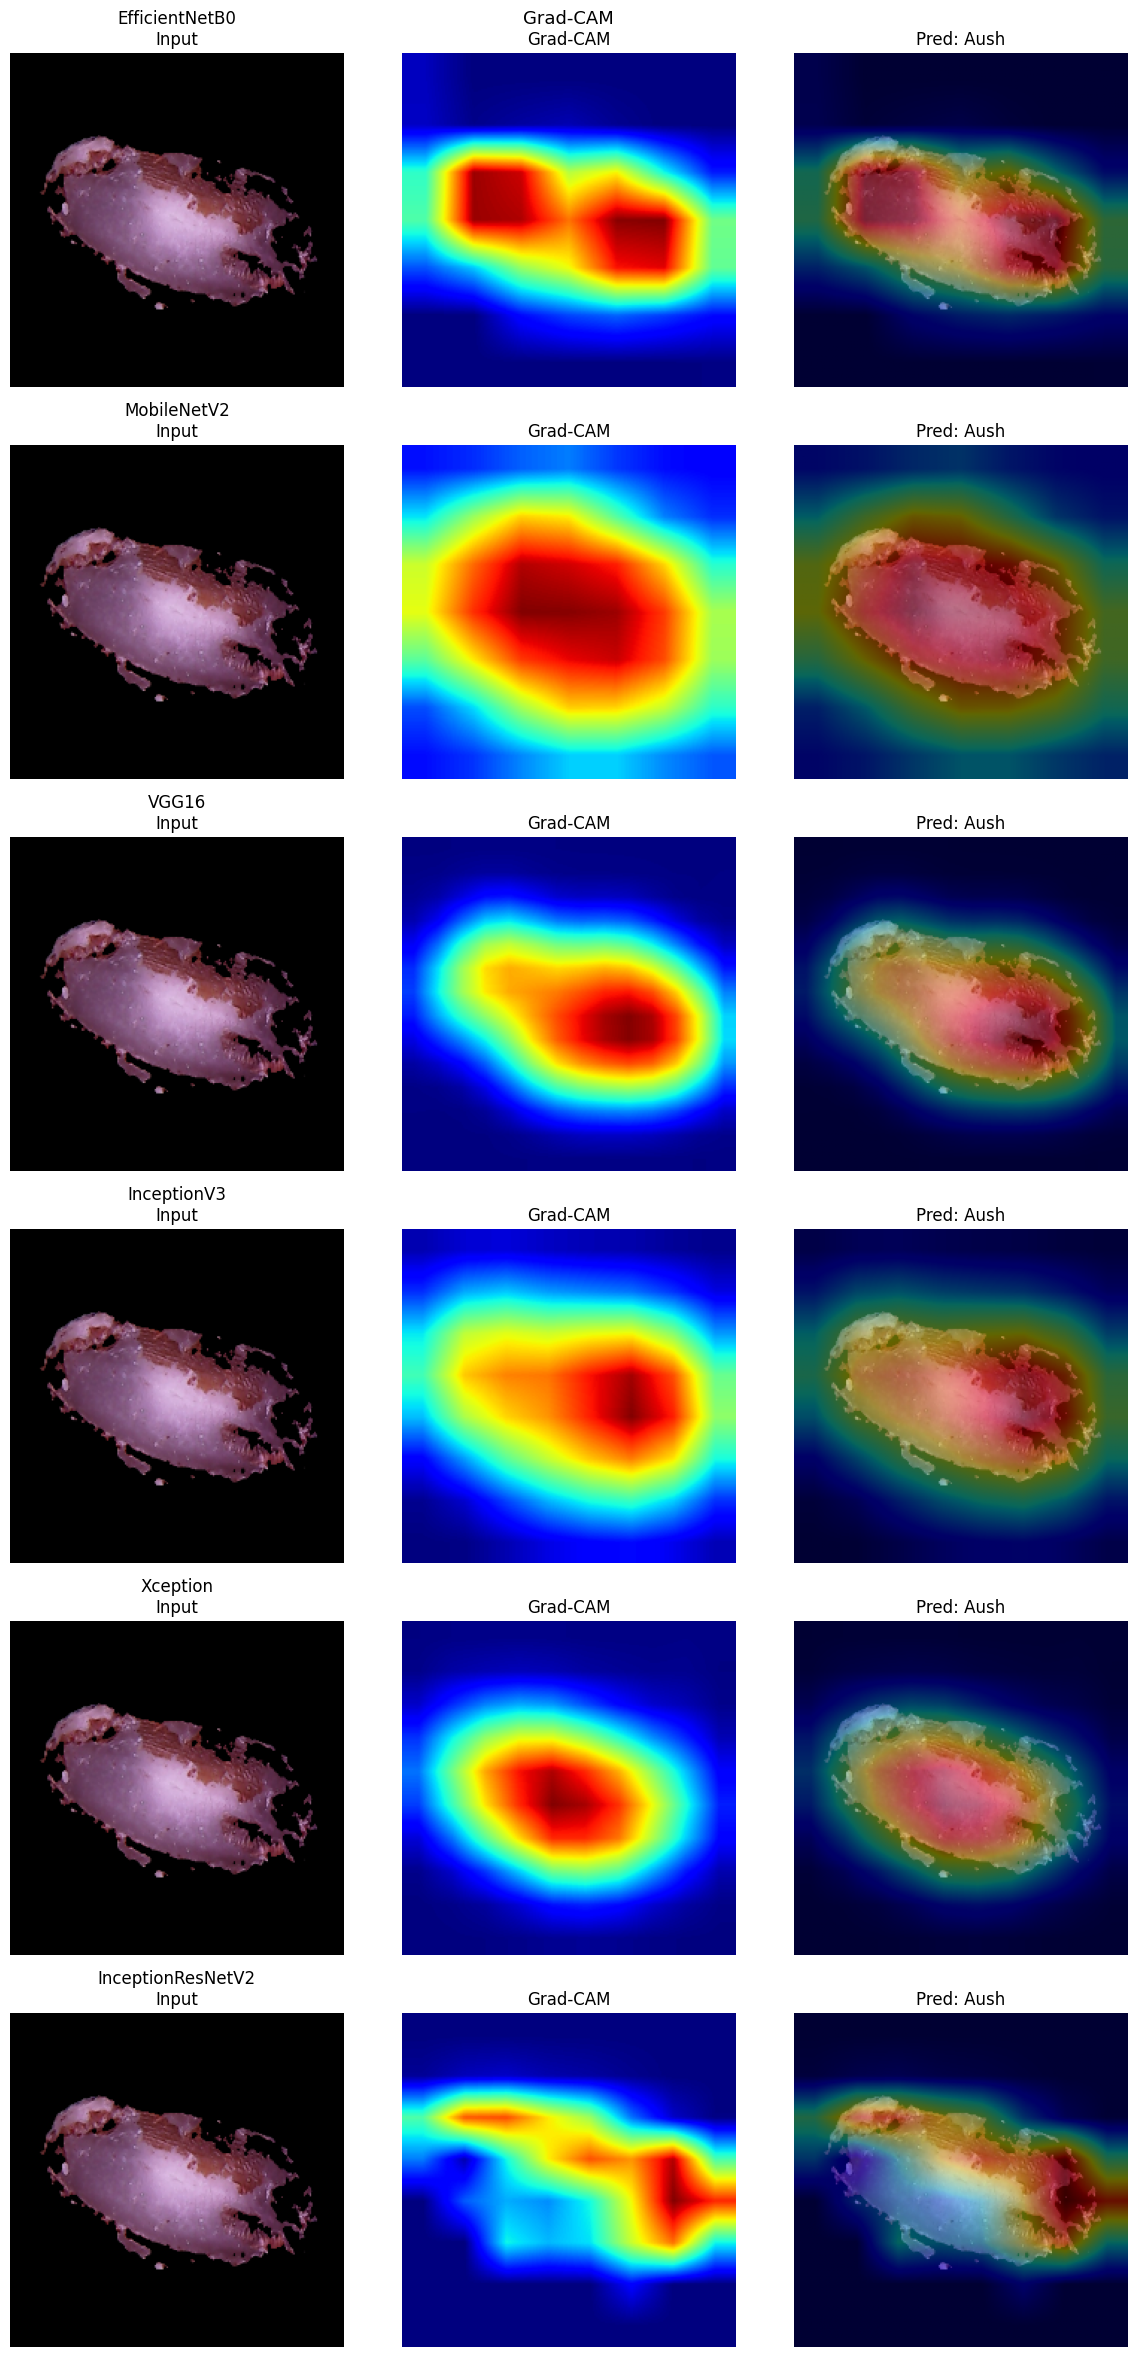

In [17]:
# Last conv layer name per architecture (torchvision internal naming)
LAST_CONV_PT = {
    'EfficientNetB0':    'features.8',
    'MobileNetV2':       'features.18',
    'VGG16':             'features.29',
    'InceptionV3':       'Mixed_7c',
    'Xception':          'backbone.act4',          # timm
    'InceptionResNetV2': 'backbone.conv2d_7b',      # timm
}

def get_gradcam_pt(img_uint8, model, conv_layer_name, model_name):
    _, mean, std, inp_size = MODEL_CONFIGS[model_name]
    tfm = make_transforms(mean, std, inp_size, train=False)
    inp = tfm(img_uint8).unsqueeze(0).to(DEVICE)

    # Hook
    activation, gradient = {}, {}

    def fwd_hook(module, inp_, out):
        activation['fmap'] = out

    def bwd_hook(module, grad_in, grad_out):
        gradient['grad'] = grad_out[0]

    # Resolve layer by name
    layer = model
    for part in conv_layer_name.split('.'):
        try:
            layer = getattr(layer, part)
        except AttributeError:
            layer = layer[int(part)]

    fh = layer.register_forward_hook(fwd_hook)
    bh = layer.register_backward_hook(bwd_hook)

    model.eval()
    output = model(inp)
    if isinstance(output, tuple): output = output[0]
    pred_idx = output.argmax(dim=1).item()
    model.zero_grad()
    output[0, pred_idx].backward()

    fh.remove(); bh.remove()

    fmap = activation['fmap'][0].detach().cpu().numpy()  # (C, H, W)
    grad = gradient['grad'][0].detach().cpu().numpy()    # (C, H, W)
    pooled = grad.mean(axis=(1, 2))                      # (C,)
    cam = np.maximum(np.einsum('c,chw->hw', pooled, fmap), 0)
    cam = cam / (cam.max() + 1e-8)
    hm  = cv2.resize(cam, IMG_SIZE)
    jet     = mpl_cm.jet(np.uint8(255 * hm))[:, :, :3]
    orig    = img_uint8 / 255.0
    overlay = np.clip(jet * 0.4 + orig * 0.6, 0, 1)
    return orig, jet, overlay, pred_idx

sample_img = segment_grain(all_paths[0])
n = len(trained_models)
fig, axes = plt.subplots(n, 3, figsize=(12, 4*n))
if n == 1: axes = axes[np.newaxis, :]
for row, (name, model) in enumerate(trained_models.items()):
    try:
        orig, hm, overlay, pred = get_gradcam_pt(
            sample_img, model, LAST_CONV_PT[name], name)
        axes[row,0].imshow(orig);    axes[row,0].set_title(f'{name}\nInput')
        axes[row,1].imshow(hm);      axes[row,1].set_title('Grad-CAM')
        axes[row,2].imshow(overlay); axes[row,2].set_title(f'Pred: {CLASS_NAMES[pred]}')
    except Exception as e:
        axes[row,0].set_title(f'{name}: {e}', fontsize=7)
    for ax in axes[row]: ax.axis('off')
plt.suptitle('Grad-CAM', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'gradcam_all.png'), dpi=150)
plt.show()

## 17. LIME

  0%|          | 0/300 [00:00<?, ?it/s]

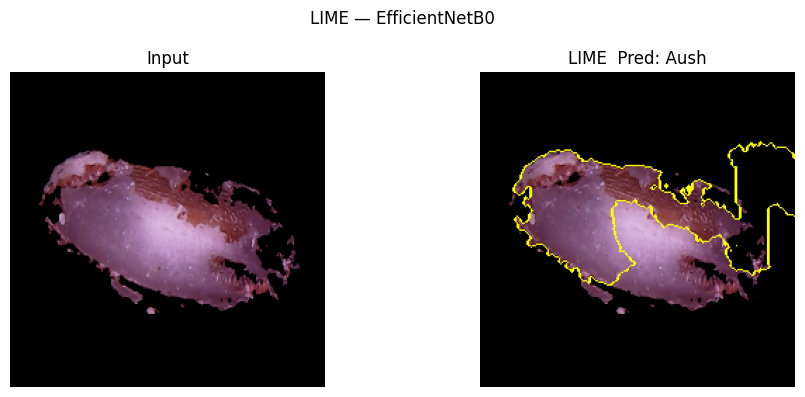

  0%|          | 0/300 [00:00<?, ?it/s]

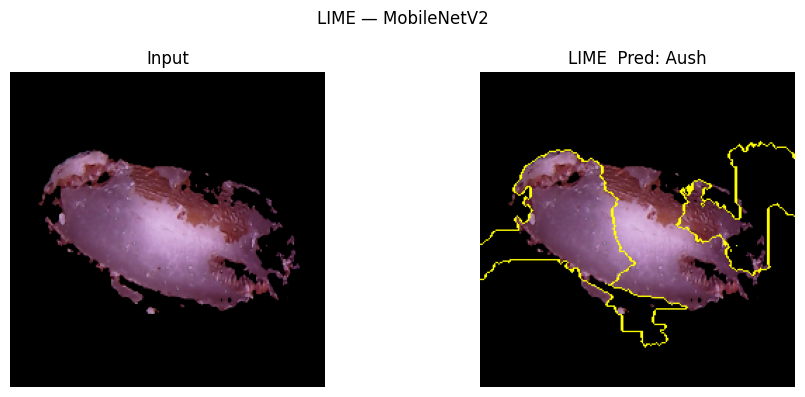

  0%|          | 0/300 [00:00<?, ?it/s]

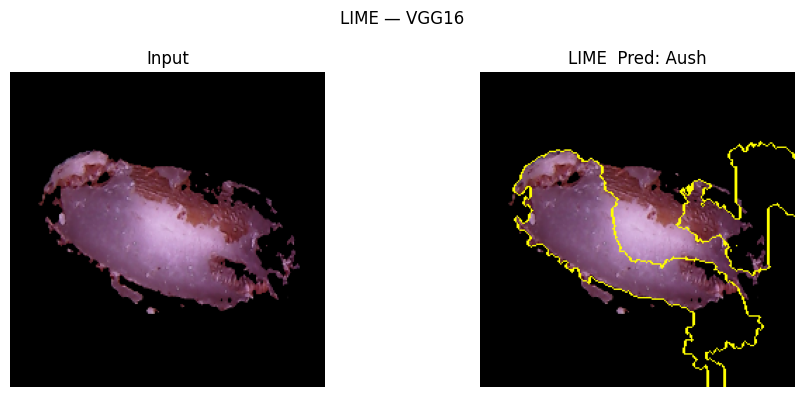

  0%|          | 0/300 [00:00<?, ?it/s]

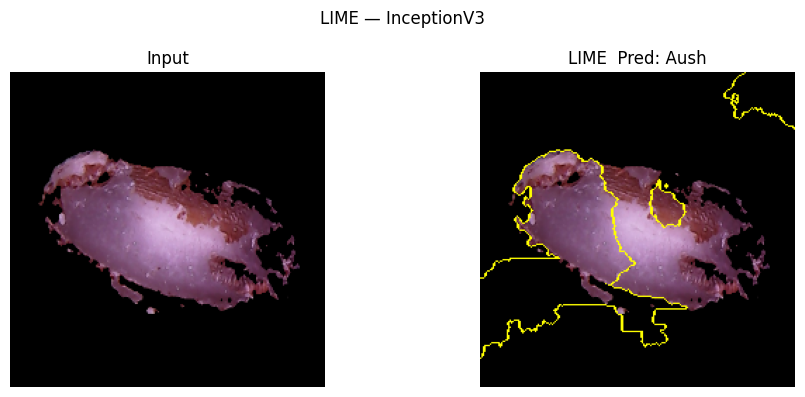

  0%|          | 0/300 [00:00<?, ?it/s]

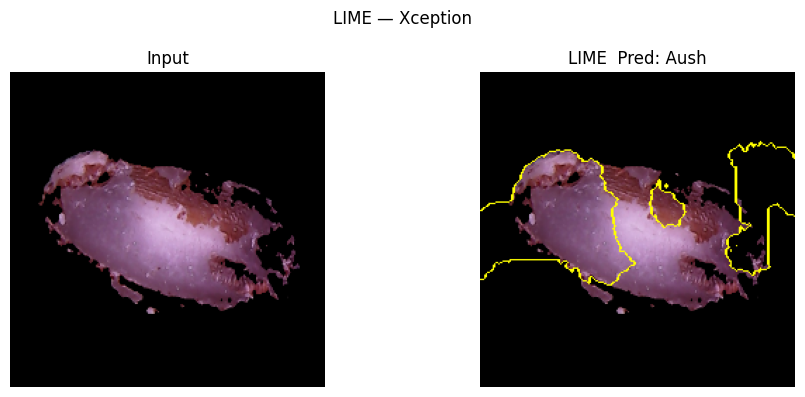

  0%|          | 0/300 [00:00<?, ?it/s]

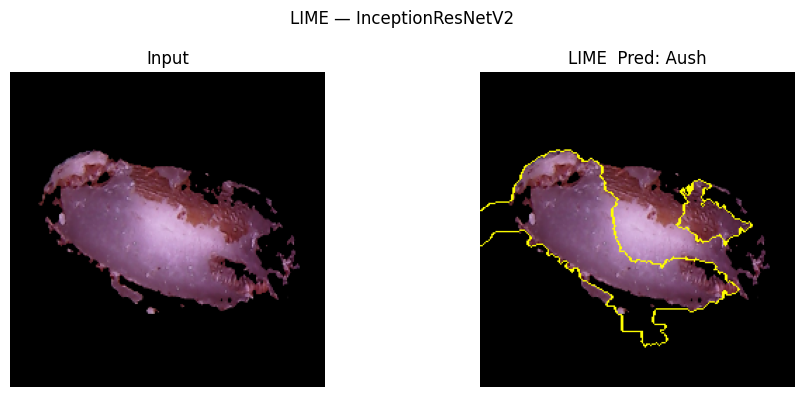

In [18]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

def explain_lime(img_uint8, model, model_name, num_samples=300):
    _, mean, std, inp_size = MODEL_CONFIGS[model_name]
    tfm = make_transforms(mean, std, inp_size, train=False)

    def predict_fn(imgs_np):
        # imgs_np: (N, H, W, 3) uint8
        batch = torch.stack([tfm(img) for img in imgs_np]).to(DEVICE)
        with torch.no_grad():
            out = model(batch)
            if isinstance(out, tuple): out = out[0]
        return torch.softmax(out, dim=1).cpu().numpy()

    explainer = lime_image.LimeImageExplainer()
    exp = explainer.explain_instance(
        img_uint8, predict_fn,
        top_labels=NUM_CLASSES, hide_color=0, num_samples=num_samples
    )
    top = exp.top_labels[0]
    temp, mask = exp.get_image_and_mask(
        top, positive_only=True, num_features=5, hide_rest=False)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(img_uint8); axes[0].set_title('Input'); axes[0].axis('off')
    axes[1].imshow(mark_boundaries(np.clip(temp/255.0, 0, 1), mask))
    axes[1].set_title(f'LIME  Pred: {CLASS_NAMES[top]}')
    axes[1].axis('off')
    plt.suptitle(f'LIME — {model_name}', fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'lime', f'lime_{model_name}.png'), dpi=150)
    plt.show()

sample_img = segment_grain(all_paths[0])
for name, model in trained_models.items():
    explain_lime(sample_img, model, name)

## 18. Results Summary

            Model  Accuracy  Precision  Recall     F1    AUC
      Soft Voting    0.9625     0.9629  0.9625 0.9624 0.9987
  Weighted Voting    0.9617     0.9621  0.9617 0.9616 0.9987
      Hard Voting    0.9542     0.9561  0.9542 0.9542    NaN
         Xception    0.9308     0.9409  0.9308 0.9312 0.9986
            VGG16    0.9258     0.9308  0.9258 0.9246 0.9975
   EfficientNetB0    0.9142     0.9191  0.9142 0.9136 0.9968
InceptionResNetV2    0.8775     0.9045  0.8775 0.8778 0.9964
      MobileNetV2    0.8708     0.8974  0.8708 0.8631 0.9937
      InceptionV3    0.8467     0.8821  0.8467 0.8479 0.9910


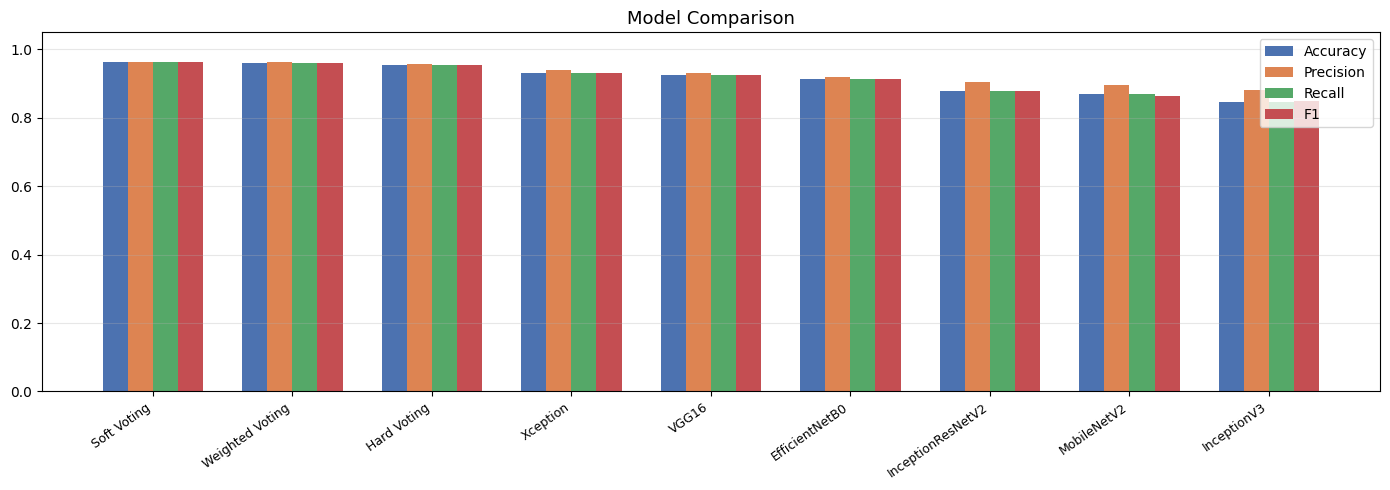

In [19]:
rows = []
for name, rep in all_reports.items():
    row = {
        'Model':     name,
        'Accuracy':  round(rep['accuracy'], 4),
        'Precision': round(rep['macro avg']['precision'], 4),
        'Recall':    round(rep['macro avg']['recall'], 4),
        'F1':        round(rep['macro avg']['f1-score'], 4),
    }
    if 'macro_auc' in rep: row['AUC'] = rep['macro_auc']
    rows.append(row)

df = (pd.DataFrame(rows)
        .sort_values('Accuracy', ascending=False)
        .reset_index(drop=True))
print(df.to_string(index=False))
df.to_csv(os.path.join(OUTPUT_DIR, 'results_summary.csv'), index=False)

fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(df)); w = 0.18
ax.bar(x-1.5*w, df['Accuracy'],  w, label='Accuracy',  color='#4C72B0')
ax.bar(x-0.5*w, df['Precision'], w, label='Precision', color='#DD8452')
ax.bar(x+0.5*w, df['Recall'],    w, label='Recall',    color='#55A868')
ax.bar(x+1.5*w, df['F1'],        w, label='F1',        color='#C44E52')
ax.set_xticks(x)
ax.set_xticklabels(df['Model'], rotation=35, ha='right', fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_title('Model Comparison', fontsize=13)
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'model_comparison.png'), dpi=150)
plt.show()

## 19. Single Image Inference

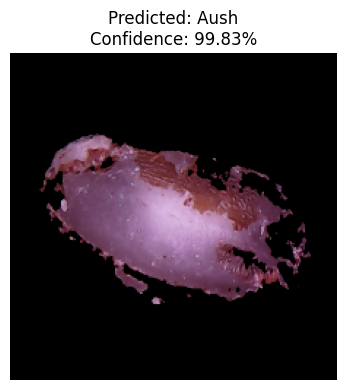

{'class': 'Aush', 'confidence': 0.9983}


In [20]:
def predict(image_path, voting='weighted'):
    img_uint8 = segment_grain(image_path)
    probas = []
    for name, model in trained_models.items():
        _, mean, std, inp_size = MODEL_CONFIGS[name]
        tfm = make_transforms(mean, std, inp_size, train=False)
        inp = tfm(img_uint8).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            out = model(inp)
            if isinstance(out, tuple): out = out[0]
        probas.append(torch.softmax(out, dim=1).cpu().numpy()[0])
    probas = np.array(probas)

    if voting == 'hard':
        preds = np.argmax(probas, axis=1)
        mode_result = stats.mode(preds)
        idx   = int(mode_result.mode[0] if hasattr(mode_result.mode, '__len__') else mode_result.mode)
        conf  = float((preds == idx).mean())
    elif voting == 'weighted':
        avg  = np.average(probas, axis=0, weights=weights_ens)
        idx  = int(np.argmax(avg)); conf = float(avg[idx])
    else:
        avg  = probas.mean(axis=0)
        idx  = int(np.argmax(avg)); conf = float(avg[idx])

    plt.figure(figsize=(4, 4))
    plt.imshow(img_uint8)
    plt.title(f'Predicted: {CLASS_NAMES[idx]}\nConfidence: {conf:.2%}')
    plt.axis('off'); plt.tight_layout(); plt.show()
    return {'class': CLASS_NAMES[idx], 'confidence': round(conf, 4)}

print(predict(all_paths[0]))

---
## Done. Outputs saved to `./outputs/`